# Part 2: ViT from scratch

Attach the soil competition data and soil-cv-utils version 10.
Use Internet, 2 x T4 GPUs, and the WANDB_API_KEY secret. Then Save & Run All.
Code comes from the dataset. Outputs stay in /kaggle/working. No CV-summary run is made.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["SOILCV_VIT_FAMILY"] = "scratch"
os.environ["SOILCV_VIT_OUTPUT_DIR"] = "/kaggle/working/part2_scratch"
os.environ["TORCH_HOME"] = "/tmp/soilcv-torch"
os.environ["WANDB_CACHE_DIR"] = "/tmp/soilcv-wandb-cache"
code_root = Path("/kaggle/input/datasets/denysmykhailov/soil-cv-utils")
if not (code_root / "soilcv/vit/model.py").is_file():
    paths = list(Path("/kaggle/input").rglob("soilcv/vit/model.py"))
    if len(paths) != 1:
        raise RuntimeError("Attach the matching soil-cv-utils dataset version.")
    code_root = paths[0].parents[2]
sys.path.insert(0, str(code_root))
os.environ["PYTHONPATH"] = (
    str(code_root) + os.pathsep + os.environ.get("PYTHONPATH", "")
)
from kaggle_secrets import UserSecretsClient

os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB_API_KEY")

import pandas as pd
import torch
from IPython.display import display

from soilcv.artifacts import package_identity

if (
    package_identity()["source_hash"]
    != "788545b08a93b55e34e5c0ce32a7c4fb141646aeed5cab3fc0f4740f7bbb7b44"
):
    raise RuntimeError("Select the exact code dataset version for this notebook.")
if torch.cuda.device_count() != 2:
    raise RuntimeError("Select two T4 GPUs.")
from soilcv.cnn.outputs import save_source
from soilcv.vit.analysis import collect_results, plot_learning, plot_scores
from soilcv.vit.experiments import RECIPES, ROOT, jobs, prepare
from soilcv.vit.outputs import export_outputs

print("GPUs:", [torch.cuda.get_device_name(i) for i in range(2)])
print("Output folder:", ROOT)

GPUs: ['Tesla T4', 'Tesla T4']
Output folder: /kaggle/working/part2_scratch


## Full photos and scale

All cameras use 2 estimated pixels/mm. Each photo keeps its shape and full area.
There is one LANCZOS resize, with no crop. The model pads only the edge for patches.
The number of patches can change. Small grains can still be lost by downsampling.
The PPM estimate still assumes no source crop. It is not a new scale measurement.

In [2]:
metadata = prepare()
save_source(ROOT)
coverage = pd.read_csv(ROOT / "coverage.csv")
assert coverage.coverage.eq(1).all()
assert coverage.missing_native_pixels.eq(0).all()
print("Study:", metadata["run_id"])
print("Hypotheses commit:", metadata["identity"]["hypotheses_commit"])
print("Photos:", len(coverage))
display(
    coverage.groupby("device")[
        ["output_width", "output_height", "actual_ppm_x", "actual_ppm_y"]
    ].agg(["min", "max"])
)

Study: scratch | photos: 162 | max patch-16 tokens: 1452
Study: 20261101T170306Z-eeb6d8f69e
Hypotheses commit: 211ba0d
Photos: 162


output_width      output_height      actual_ppm_x  \
                                 min  max           min  max          min   
device                                                                      
Motorola Edge                    313  696           313  696     1.998331   
Motorola Edge 60 Fusion          370  657           370  657     1.999391   
Samsung A52                      702  702           527  527     1.999291   
iPhone 14                        434  578           434  578     1.998630   
iPhone 16                        439  585           439  585     1.999672   

                                  actual_ppm_y            
                              max          min       max  
device                                                    
Motorola Edge            1.999608     1.998331  1.999608  
Motorola Edge 60 Fusion  2.001758     1.999391  2.001758  
Samsung A52              1.999291     1.999939  1.999939  
iPhone 14                2.000935     1.998630  2.000935  
iPhone 16                2.000811     1.999672  2.000811

## Small ViT

This is the Lecture 1 design: patch embedding, CLS, attention blocks and MLPs.
2-D sine/cosine positions allow different photo shapes. Each CLS sees its full photo.
We average the photo features and use one curve head and one EMD loss per soil.
We test patch 16, patch 32, and no warmup. The model starts with random weights.

In [3]:
display(pd.DataFrame(RECIPES))
print((code_root / "HYPOTHESES.md").read_text())
print("Standard jobs:", 4 * len(RECIPES))
print("Camera diagnostic jobs:", len(jobs()) - 4 * len(RECIPES))

,target_ppm,augmentation,weight_decay,schedule,warmup,accumulation_steps,deterministic,drop_path,image_schema,pooling,...,heads,dropout,max_tokens,backbone_lr,head_lr,layer_decay,epochs,patience,id,hypothesis
0,2.0,True,0.05,warmup_cosine,3,2,True,0.1,full_photo_ppm_v1,equal_photo_features,...,3,0.1,2048,0.0003,0.0003,1.0,32,7,vit-scratch-p16,H-VIT-01
1,2.0,True,0.05,warmup_cosine,3,2,True,0.1,full_photo_ppm_v1,equal_photo_features,...,3,0.1,2048,0.0003,0.0003,1.0,32,7,vit-scratch-p32,H-VIT-02
2,2.0,True,0.05,warmup_cosine,0,2,True,0.1,full_photo_ppm_v1,equal_photo_features,...,3,0.1,2048,0.0003,0.0003,1.0,32,7,vit-scratch-no-warmup,H-VIT-03


# Hypotheses before the MIL run

This run uses full-coverage sample-level MIL. Only MIL checkpoints are supported by inference.

Use the same four sample folds. Every photo of a sample stays in one fold.
One training item is one complete soil sample. Use all grid tiles of all its photos in train, validation and test. Do not randomly drop tiles or photos.

Use 64 mm crops and a full-image grid. Edge tiles overlap when needed. Check the union of rectangles for every photo. Use overlap-corrected area weights within each photo, then equal photo weights within each sample. Pool CNN features before the curve head. Compute EMD once per sample.

Each resolution gets its own cache directly from the same native rectangles with LANCZOS. There is no second resize. 224 and 288 use the same photos, bag weights, updates, folds, and physical area.

Budget: 16 epochs, early stop after 5 epochs without improvement. Two complete sample bags per optimizer update. Frozen BN statistics for all ResNet runs. 

## Train and choose checkpoints

Keep the same four sample folds. All photos of a soil stay together.
Each GPU runs one fold. We use all photos of every sample, with one sample loss.
After three fixed first epochs, a checkpoint must have no worse EMD and no worse
camera disagreement. At least one must be better. Both values are logged in W&B.
This can stop early when the two values disagree. There is no weighted sum.
The rule does not prove good transfer to iPhone.

Camera jobs use only Motorola or only Samsung for training. The same held-out
paired soils give same-camera and cross-camera errors. Both validation cameras
affect checkpoint choice. This is a stress test, not an untouched device test.

In [4]:
subprocess.run([sys.executable, "-m", "soilcv.vit.launcher"], check=True)
status = json.loads((ROOT / "status.json").read_text())
assert len(status["jobs"]) == len(jobs())
assert all(job["state"] == "complete" for job in status["jobs"])
print("Complete fold jobs:", len(status["jobs"]))

started vit-scratch-p16 0 None GPU 0
started vit-scratch-p16 1 None GPU 1
complete vit-scratch-p16 1 None
started vit-scratch-p16 2 None GPU 1
complete vit-scratch-p16 0 None
started vit-scratch-p16 3 None GPU 0
complete vit-scratch-p16 2 None
started vit-scratch-p32 0 None GPU 1
complete vit-scratch-p16 3 None
started vit-scratch-p32 1 None GPU 0
complete vit-scratch-p32 0 None
started vit-scratch-p32 2 None GPU 1
complete vit-scratch-p32 1 None
started vit-scratch-p32 3 None GPU 0
complete vit-scratch-p32 2 None
started vit-scratch-no-warmup 0 None GPU 1
complete vit-scratch-p32 3 None
started vit-scratch-no-warmup 1 None GPU 0
complete vit-scratch-no-warmup 0 None
started vit-scratch-no-warmup 2 None GPU 1
complete vit-scratch-no-warmup 1 None
started vit-scratch-no-warmup 3 None GPU 0
complete vit-scratch-no-warmup 2 None
started vit-scratch-p16 0 Motorola GPU 1
complete vit-scratch-no-warmup 3 None
started vit-scratch-p16 1 Motorola GPU 0
complete vit-scratch-p16 0 Motorola
starte

## Results and four-fold ensembles

OOF uses one held-out model for each soil. Each test CSV averages all four fold models
of one recipe. Camera diagnostic runs stay out of the main ranking.
Each fold also checks all test predictions after reloading its saved weights.

,experiment,run_id,arch,cv_emd,fold_mean,fold_std,camera_paired_samples,motorola_emd,samsung_emd,camera_disagreement,gpu_hours,peak_gpu_mb,epochs_per_fold,best_epochs,public_lb,private_lb
0,vit-scratch-no-warmup,20261101T170306Z-eeb6d8f69e,scratch_vit,79.173,79.173,15.686,21,87.318,84.379,9.293,0.103,188.954,"11,14,11,11","3,6,3,3",not submitted,not available
1,vit-scratch-p16,20261101T170306Z-eeb6d8f69e,scratch_vit,80.061,80.061,14.273,21,85.841,85.543,3.111,0.117,188.954,"20,11,11,11","12,3,3,3",not submitted,not available
2,vit-scratch-p32,20261101T170306Z-eeb6d8f69e,scratch_vit,83.470,83.470,9.387,21,88.720,84.588,5.613,0.093,157.467,"11,11,12,11","3,3,4,3",not submitted,not available


,experiment,run_id,train_camera,domain_paired_samples,e_same,e_cross,delta_domain,camera_disagreement,gpu_hours,peak_gpu_mb
0,vit-scratch-p16,20261101T170306Z-eeb6d8f69e,Motorola,21,83.643,83.777,0.135,2.796,0.065,149.669
1,vit-scratch-p16,20261101T170306Z-eeb6d8f69e,Samsung,21,84.646,84.630,-0.016,0.141,0.072,180.901


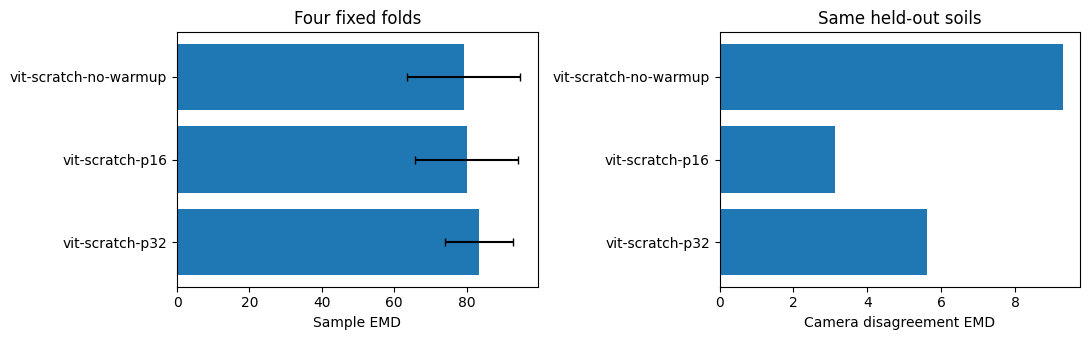

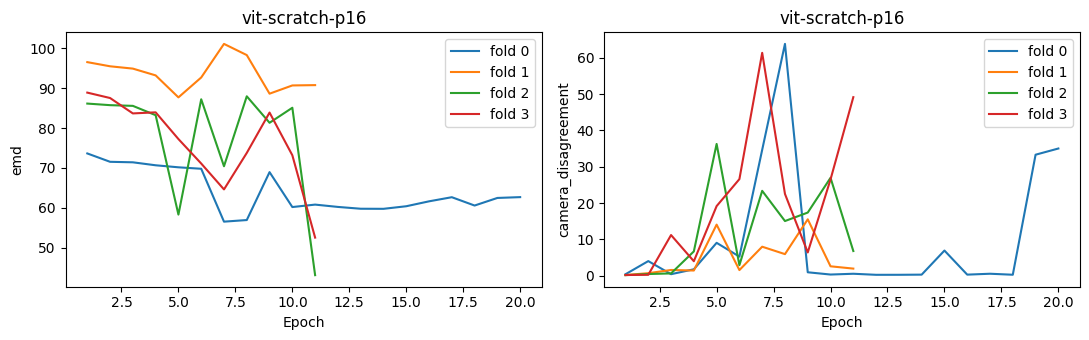

# ViT results

Run ID: `20261101T170306Z-eeb6d8f69e`.
Code hash: `788545b08a93b55e34e5c0ce32a7c4fb141646aeed5cab3fc0f4740f7bbb7b44`.

The same four sample folds are used for every model. Lower EMD is better.
Each test CSV is the mean of four fold models of the same recipe.

| Recipe | OOF EMD | Fold std | Camera gap | Fit GPU hours | Peak MB |
| --- | ---: | ---: | ---: | ---: | ---: |
| vit-scratch-no-warmup | 79.173 | 15.686 | 9.293 | 0.103 | 189 |
| vit-scratch-p16 | 80.061 | 14.273 | 3.111 | 0.117 | 189 |
| vit-scratch-p32 | 83.470 | 9.387 | 5.613 | 0.093 | 157 |

The best standard OOF recipe is vit-scratch-no-warmup.
Camera gap means EMD between Motorola and Samsung predictions for the same held-out soil.
It is not a label error. The raw pairs are in results/camera_pairs.csv.

## Cross-camera check

These models train on one camera only. The physical sample folds stay the same.
Both errors use the same held-out soils with both cameras.

| Training camera | Paired soils | Same EMD 

In [5]:
results, oof_predictions, camera_domains = collect_results()
display(results.round(3))
display(camera_domains.round(3))
import matplotlib.pyplot as plt

figure = plot_scores(results)
figure.savefig(ROOT / "results/scores.png", dpi=150)
plt.show()
figure = plot_learning()
figure.savefig(ROOT / "results/learning.png", dpi=150)
plt.show()
print((ROOT / "VIT_RESULTS.md").read_text())

## Kaggle Outputs

Save weights, OOF curves, all test CSVs, camera checks, configs, logs, code and environment.
The best standard recipe also gives a top-level submission.csv. No competition submission is sent.
The data has only 24 labelled soils. Fold std is not a confidence interval.

In [6]:
folder = export_outputs()
submission = pd.read_csv(ROOT.parent / "submission.csv")
display(submission.head())
print("Submission shape:", submission.shape)
print("Study files:", folder)
print("W&B: https://wandb.ai/public-team/soil-grain-size")

Saved study: /kaggle/working/part2_scratch | top-level submission: /kaggle/working/submission.csv


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,HPC_Airbus BS6-3,1.635629,3.375841,8.367337,19.810671,32.461496,43.671602,56.921486,76.980553,93.877366,99.706910,100.0
1,HPC_Audorfring,1.593321,3.284802,8.062948,18.734371,30.589067,41.597390,55.254734,76.037381,93.661551,99.704449,100.0
2,HPC_Muenster_BS6_9_0-10m,1.693088,3.450239,8.057352,17.107648,26.823587,36.020334,50.055456,72.534027,92.582350,99.638255,100.0
3,HPC_Airbus BS10-4bis7,1.668968,3.446860,8.566950,20.391948,33.388711,44.611654,57.672198,77.423919,93.979350,99.708295,100.0
4,HPC_Airbus BS12-5bis8,1.719373,3.553864,8.853528,21.154462,34.545824,45.725641,58.581124,77.976458,94.115373,99.710722,100.0


Submission shape: (10, 12)
Study files: /kaggle/working/part2_scratch
W&B: https://wandb.ai/public-team/soil-grain-size
